# EDA-06 — Biaya, microstructure, dan break-even

Notebook **deskriptif**: tidak ada sinyal, model, atau backtest. Tujuannya satu keputusan:
apakah ada kombinasi **sesi × horizon/barrier** di mana ruang gerak harga cukup besar dibanding
biaya, sehingga scalping USDJPY layak dilanjutkan ke notebook label/fitur (EDA-07).

Pertanyaan yang dijawab:

- **C1** — seberapa besar dan seberapa buruk ekor spread?
- **C2** — kapan spread melebar (volatilitas, jam tetap, rollover)?
- **C3** — berapa biaya per skenario (normal, stres, slippage)?
- **C4** — berapa **edge minimum** agar impas, baik untuk taruhan arah N-menit maupun
  untuk SL/TP tetap (50/70 point) dan SL/TP berbasis ATR?

Jalankan sekali dari atas ke bawah. Tidak ada gerbang review per sel; gerbang keputusan ada di Bagian 7.

In [1]:
# Kontrak Notebook 06 — dicetak verbatim sebagai output pertama (wajib).
KONTRAK_06 = """- Holdout: data 2026 TIDAK dimuat sama sekali (dikunci untuk Lapisan 3). Asersi: max(utc) < 2026-01-01.
- Universe: strata A + B tahun 2023-2025, dikurangi strata C (jendela anomali). B (H1-2023, regime vol tinggi) dilaporkan terpisah dan TIDAK dihitung pada kriteria K2.
- Otoritas biaya: config spread.cost_basis.by_session (normal) dan spread.stress_bands.p95.by_session (stres). Bukan spread.default (1,5 pip, blok lama). Slippage = skenario +0 / +0,1 / +0,3 pip (tidak terukur dari OHLC).
- Entri TANPA sinyal, setiap STRIDE bar, dua sisi (buy + sell) digabung = arah acak. Hasilnya LAJU DASAR, bukan strategi dan bukan backtest.
- Harga close/high/low = BID. Buy masuk di ask = bid + spread, sell masuk di bid dan keluar di ask. Spread konstan per sesi bar entri (skenario).
- Barrier = first-passage pada high/low M1 bar SESUDAH bar entri. SL dan TP tersentuh di bar yang sama dihitung SL (pesimis), pangsanya dilaporkan. Timeout HORIZON menit keluar di close.
- ATR M5(14) dari bar M5 yang SUDAH SELESAI saat keputusan (akhir bar M1), dibekukan saat entri; SL/TP tidak berubah setelah entri.
- Entri dibuang bila jendelanya menyeberangi gap atau jendela anomali, ATR belum tersedia, atau sesi 'Off'. Nol imputasi; jumlah buang dilaporkan.
- Edge minimum yang dibutuhkan: delta = -E / (TP + SL) dalam poin persentase peluang TP-duluan; E = ekspektasi dasar per entri dalam pip (sudah memuat spread dan timeout).
- Gerbang (dikunci sebelum menjalankan): K1 delta_normal <= 3,0 pp DAN delta_stres <= 5,0 pp; K2 delta_normal <= 3,0 pp pada >= 4 dari 5 semester A; K3 n >= 1000 entri-sisi dan >= 100 hari; K4 p_none <= 50% (barrier harus benar-benar tercapai dalam horizon; barrier raksasa yang hampir selalu timeout membuat delta tampak kecil secara semu).
- Jumlah irisan yang diuji dicatat; lolos gerbang bukan bukti edge, hanya izin lanjut ke EDA-07."""
print(KONTRAK_06)

- Holdout: data 2026 TIDAK dimuat sama sekali (dikunci untuk Lapisan 3). Asersi: max(utc) < 2026-01-01.
- Universe: strata A + B tahun 2023-2025, dikurangi strata C (jendela anomali). B (H1-2023, regime vol tinggi) dilaporkan terpisah dan TIDAK dihitung pada kriteria K2.
- Otoritas biaya: config spread.cost_basis.by_session (normal) dan spread.stress_bands.p95.by_session (stres). Bukan spread.default (1,5 pip, blok lama). Slippage = skenario +0 / +0,1 / +0,3 pip (tidak terukur dari OHLC).
- Entri TANPA sinyal, setiap STRIDE bar, dua sisi (buy + sell) digabung = arah acak. Hasilnya LAJU DASAR, bukan strategi dan bukan backtest.
- Harga close/high/low = BID. Buy masuk di ask = bid + spread, sell masuk di bid dan keluar di ask. Spread konstan per sesi bar entri (skenario).
- Barrier = first-passage pada high/low M1 bar SESUDAH bar entri. SL dan TP tersentuh di bar yang sama dihitung SL (pesimis), pangsanya dilaporkan. Timeout HORIZON menit keluar di close.
- ATR M5(14) dari bar M5 yang SU

In [2]:
"""Setup lingkungan dan kunci versi."""
import importlib.metadata
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from scipy import stats


def find_project_root(start: Path) -> Path:
    """Cari root proyek (pyproject.toml + src/) dari cwd ke atas."""
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "src").is_dir():
            return candidate
    raise RuntimeError("PROJECT_ROOT tidak ditemukan")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.broker_time import wall_clock_series  # noqa: E402
from src.utils.config import load_config  # noqa: E402

sys.path.insert(0, str(PROJECT_ROOT / "notebooks/scalping"))
from _eda_common import (  # noqa: E402
    EXPECTED_FINGERPRINT,
    SESSION_ORDER,
    add_labels,
    session_fingerprint,
)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("python       :", sys.version.split()[0])
for package in ("pandas", "numpy", "pyarrow", "matplotlib", "scipy", "tzdata"):
    print(f"  {package:11s}: {importlib.metadata.version(package)}")

assert importlib.metadata.version("tzdata") == "2026.5", "tzdata harus 2026.5 (Kontrak 00)"
assert (
    int(importlib.metadata.version("pandas").split(".")[0]) == 2
), "Notebook WAJIB jalan di venv kanonik (pandas 2.x)."

assert (
    session_fingerprint() == EXPECTED_FINGERPRINT
), "Definisi sesi berubah vs Notebook 00 -STOP, kembalikan ke kontrak."
print("PASS: definisi sesi identik dengan Notebook 00 (sidik jari cocok).")

PROJECT_ROOT : D:\ANN
python       : 3.12.8
  pandas     : 2.2.3
  numpy      : 1.26.4
  pyarrow    : 17.0.0
  matplotlib : 3.10.9
  scipy      : 1.17.1
  tzdata     : 2026.5
PASS: definisi sesi identik dengan Notebook 00 (sidik jari cocok).


In [3]:
"""Parameter terkunci (diubah HANYA sebelum menjalankan, tidak sesudah melihat hasil)."""
config = load_config("data")
SYMBOL = config["mt5"]["symbol"]
PIP_SIZE = float(config["spread"]["pip_size"][SYMBOL])
ANOMALY_WINDOWS = tuple((w["start"], w["end"]) for w in config["validation"]["anomaly_windows"])
SESSIONS = [label for label in SESSION_ORDER if label != "Off"]

YEARS = (2023, 2024, 2025)  # 2026 = holdout, TIDAK dimuat
HOLDOUT_START = pd.Timestamp("2026-01-01", tz="UTC")

# Biaya (pip). Otoritas: cost_basis (normal) dan stress_bands.p95 (stres).
COST_DEFAULT = float(config["spread"]["cost_basis"]["default"])
COST_NORMAL = {k: float(v) for k, v in config["spread"]["cost_basis"]["by_session"].items()}
COST_STRESS = {
    k: float(v) for k, v in config["spread"]["stress_bands"]["p95"]["by_session"].items()
}
STRESS_MULTIPLIER = float(config["spread"].get("stress_multiplier", 2.0))
SCENARIOS = {"normal": COST_NORMAL, "stres": COST_STRESS}
SLIPPAGE_PIPS = (0.0, 0.1, 0.3)

# Barrier
HORIZON = 120  # menit, batas waktu posisi
STRIDE = 5  # entri setiap 5 bar M1
FIXED_COMBOS = {  # nama = SL/TP dalam POINT; nilai = (SL, TP) dalam PIP
    "FIX_50_70": (5.0, 7.0),
    "FIX_30_45": (3.0, 4.5),
    "FIX_100_140": (10.0, 14.0),
}
ATR_K = (0.75, 1.0, 1.5)
ATR_RR = (1.0, 1.4, 2.0)
N_DIRECTION = (5, 15, 30, 60)

# Gerbang (dikunci)
K1_NORMAL_PP = 3.0
K1_STRESS_PP = 5.0
K2_MIN_SEM = 4
K3_MIN_N = 1000
K3_MIN_DAYS = 100
K4_MAX_NONE = 0.50

N_BOOT = 1000
RNG = np.random.default_rng(20261010)
REPORT_DIR = PROJECT_ROOT / "reports/eda" / date.today().isoformat()
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print(f"symbol={SYMBOL} | pip={PIP_SIZE} | tahun={YEARS} | holdout >= {HOLDOUT_START:%Y-%m-%d}")
print("cost_basis.default :", COST_DEFAULT, "pip")
print("cost_basis sesi    :", COST_NORMAL)
print("stress p95 sesi    :", COST_STRESS, "| stress_multiplier (config):", STRESS_MULTIPLIER)
print(f"barrier: HORIZON={HORIZON} mnt, STRIDE={STRIDE}, tetap={list(FIXED_COMBOS)}")
print(f"ATR: k={ATR_K}, RR={ATR_RR} -> {len(ATR_K) * len(ATR_RR)} kombinasi")
print(
    f"gerbang: K1 {K1_NORMAL_PP}/{K1_STRESS_PP} pp | K2 >= {K2_MIN_SEM}/5 semester | K3 n>={K3_MIN_N}, hari>={K3_MIN_DAYS} | K4 p_none<={K4_MAX_NONE:.0%}"
)
print("laporan ->", REPORT_DIR)
assert set(SESSIONS) == set(COST_NORMAL) == set(COST_STRESS), "sesi config harus 4 sesi"

symbol=USDJPY | pip=0.01 | tahun=(2023, 2024, 2025) | holdout >= 2026-01-01
cost_basis.default : 0.65 pip
cost_basis sesi    : {'London': 0.61, 'NewYork': 0.69, 'Tokyo': 0.62, 'Sydney': 0.8}
stress p95 sesi    : {'London': 0.8, 'NewYork': 1.2, 'Tokyo': 0.9, 'Sydney': 1.5} | stress_multiplier (config): 2.0
barrier: HORIZON=120 mnt, STRIDE=5, tetap=['FIX_50_70', 'FIX_30_45', 'FIX_100_140']
ATR: k=(0.75, 1.0, 1.5), RR=(1.0, 1.4, 2.0) -> 9 kombinasi
gerbang: K1 3.0/5.0 pp | K2 >= 4/5 semester | K3 n>=1000, hari>=100 | K4 p_none<=50%
laporan -> D:\ANN\reports\eda\2026-10-10


In [4]:
"""Muat M1 2023-2025, bentuk strata A/B/C, siapkan array numpy."""
COLUMNS = ["time", "broker_time_raw", "high", "low", "close", "spread_pips"]
frames = [
    pd.read_parquet(
        PROJECT_ROOT / "data/processed/M1" / f"usdjpy_m1_{year}.parquet", columns=COLUMNS
    )
    for year in YEARS
]
m1 = pd.concat(frames, ignore_index=True)
m1["utc"] = pd.to_datetime(m1["time"], utc=True)
m1["wall"] = wall_clock_series(m1["broker_time_raw"])
m1["broker_day"] = m1["wall"].dt.normalize()
# Holdout ditetapkan per HARI BROKER: bar tepi (UTC 31 Des malam = hari broker 1 Jan 2026) ikut dikeluarkan.
holdout_rows = m1["broker_day"] >= pd.Timestamp("2026-01-01")
print(f"bar tepi holdout dikeluarkan (hari broker >= 2026-01-01): {int(holdout_rows.sum()):,}")
m1 = m1[~holdout_rows].sort_values("utc", kind="mergesort").reset_index(drop=True)
m1 = add_labels(m1)
m1["sem"] = (
    m1["broker_day"].dt.year.astype(str) + "H" + np.where(m1["broker_day"].dt.month <= 6, "1", "2")
)

assert m1["utc"].max() < HOLDOUT_START, "data 2026 tidak boleh ada (holdout)"
assert m1["utc"].is_monotonic_increasing

wall_date = m1["broker_day"]
b_mask = (wall_date >= pd.Timestamp("2023-01-01")) & (wall_date <= pd.Timestamp("2023-06-30"))
c_mask = pd.Series(False, index=m1.index)
for start, end in ANOMALY_WINDOWS:
    c_mask |= (wall_date >= pd.Timestamp(start)) & (wall_date <= pd.Timestamp(end))
a_mask = ~(b_mask | c_mask)
n_a, n_b, n_c = int(a_mask.sum()), int(b_mask.sum()), int(c_mask.sum())

print(f"bar dimuat={len(m1):,} | A={n_a:,} B={n_b:,} C={n_c:,} | hari broker={wall_date.nunique()}")
assert n_b == 185_248, f"B harus 185.248, dapat {n_b}"
assert not (b_mask & c_mask).any(), "B dan C tidak boleh tumpang tindih"
assert n_a + n_b + n_c == len(m1)
assert (
    int((m1.loc[a_mask, "session_label"] == "Off").sum()) == 0
), "strata A tidak boleh punya bar Off"
print(
    "PASS: strata konsisten dengan Lapisan 1 (B=185.248), partisi utuh, tanpa bar Off di A, tanpa 2026."
)

# Array numpy (dipakai simulator barrier)
N_BARS = len(m1)
CL = m1["close"].to_numpy("float64")
HI = m1["high"].to_numpy("float64")
LO = m1["low"].to_numpy("float64")
UTC_NS = (
    m1["utc"].dt.tz_convert("UTC").dt.tz_localize(None).to_numpy("datetime64[ns]").astype("int64")
)
C_ARR = c_mask.to_numpy()
C_CUM = np.concatenate([[0], np.cumsum(C_ARR)])
SESS_ARR = m1["session_label"].to_numpy()
DAY_ARR = pd.factorize(m1["broker_day"])[0].astype("int32")
SEM_ARR = m1["sem"].to_numpy()
STRATA_ARR = np.where(b_mask.to_numpy(), "B", np.where(a_mask.to_numpy(), "A", "C"))
A_FRAME = m1[a_mask]
B_FRAME = m1[b_mask]
SEM_A = sorted(A_FRAME["sem"].unique())
print("semester strata A:", SEM_A)
assert len(SEM_A) == 5, f"harus 5 semester A, dapat {len(SEM_A)}"


def boot_mean(df: pd.DataFrame, value: str, keys: list[str]) -> pd.DataFrame:
    """Mean per grup + CI95 bootstrap klaster-hari (resample hari dagang)."""
    daily = df.groupby([*keys, "day"], observed=True)[value].agg(s="sum", c="size").reset_index()
    rows = []
    for key, g in daily.groupby(keys, observed=True):
        key = key if isinstance(key, tuple) else (key,)
        s = g["s"].to_numpy()
        c = g["c"].to_numpy()
        m = len(g)
        draw = RNG.integers(0, m, size=(N_BOOT, m))
        means = s[draw].sum(axis=1) / c[draw].sum(axis=1)
        lo, hi = np.percentile(means, [2.5, 97.5])
        rows.append((*key, s.sum() / c.sum(), lo, hi, int(c.sum()), m))
    return pd.DataFrame(rows, columns=[*keys, "mean", "lo", "hi", "n", "n_days"])


def show(df: pd.DataFrame, title: str) -> None:
    """Cetak tabel penuh sebagai teks agar tersimpan di output notebook."""
    print(title)
    print(df.to_string())
    print()

bar tepi holdout dikeluarkan (hari broker >= 2026-01-01): 0


bar dimuat=1,078,001 | A=885,854 B=185,248 C=6,899 | hari broker=778
PASS: strata konsisten dengan Lapisan 1 (B=185.248), partisi utuh, tanpa bar Off di A, tanpa 2026.


semester strata A: ['2023H2', '2024H1', '2024H2', '2025H1', '2025H2']


## Bagian 1 — Sebaran spread (C1)

Ekor yang menentukan: scalper membayar spread saat entri, bukan spread rata-rata.
Semua statistik memakai strata A; strata B ditampilkan terpisah.

In [5]:
"""C1: sebaran spread per sesi, per jam UTC, per semester."""
QUANTILES = [0.50, 0.90, 0.95, 0.99, 0.999]


def spread_summary(values: pd.Series) -> dict:
    """Ringkasan spread satu subset bar (pip)."""
    q = values.quantile(QUANTILES)
    out = {"n": len(values), "mean": float(values.mean())}
    out.update({f"p{int(p * 1000) / 10:g}": float(q.loc[p]) for p in QUANTILES})
    out["max"] = float(values.max())
    for mult in (1, 2, 3, 5):
        out[f"pangsa>{mult}x"] = float((values > mult * COST_DEFAULT).mean())
    return out


T_06_1 = pd.DataFrame(
    {
        label: spread_summary(A_FRAME.loc[A_FRAME["session_label"] == label, "spread_pips"])
        for label in SESSIONS
    }
).T
T_06_1.loc["SEMUA(A)"] = spread_summary(A_FRAME["spread_pips"])
T_06_1.loc["B (H1-2023)"] = spread_summary(B_FRAME["spread_pips"])
show(
    T_06_1.round(3),
    f"T-06-1a  Sebaran spread (pip) per sesi, strata A. Pangsa>kx = bar dengan spread > k x {COST_DEFAULT} pip",
)

hour_utc = A_FRAME["utc"].dt.hour
T_06_1B = A_FRAME.groupby(hour_utc)["spread_pips"].agg(
    n="size",
    mean="mean",
    p50="median",
    p95=lambda s: s.quantile(0.95),
    p99=lambda s: s.quantile(0.99),
)
T_06_1B["pangsa>2x"] = A_FRAME.groupby(hour_utc)["spread_pips"].apply(
    lambda s: (s > 2 * COST_DEFAULT).mean()
)
show(T_06_1B.round(3), "T-06-1b  Spread per jam UTC (strata A)")

T_06_1C = A_FRAME.pivot_table(
    index="sem", columns="session_label", values="spread_pips", aggfunc="mean"
)[SESSIONS]
T_06_1C_p95 = A_FRAME.pivot_table(
    index="sem", columns="session_label", values="spread_pips", aggfunc=lambda s: s.quantile(0.95)
)[SESSIONS]
show(T_06_1C.round(3), "T-06-1c  Mean spread per semester x sesi (pip)")
show(T_06_1C_p95.round(3), "T-06-1d  p95 spread per semester x sesi (pip)")

# Verifikasi terhadap config (cost_basis = MEAN strata A, termasuk 2026 di config; selisih kecil wajar)
for label in SESSIONS:
    measured = float(A_FRAME.loc[A_FRAME["session_label"] == label, "spread_pips"].mean())
    print(
        f"  {label:8s} mean 2023-2025 A = {measured:.2f} pip | cost_basis config = {COST_NORMAL[label]:.2f}"
    )
    assert (
        abs(measured - COST_NORMAL[label]) < 0.15
    ), f"cost_basis {label} menyimpang jauh dari data - investigasi"
print(
    "PASS: cost_basis config konsisten dengan data 2023-2025 (toleransi 0,15 pip; config memuat 2026)."
)

T-06-1a  Sebaran spread (pip) per sesi, strata A. Pangsa>kx = bar dengan spread > k x 0.65 pip
                    n   mean  p50  p90  p95  p99  p99.9   max  pangsa>1x  pangsa>2x  pangsa>3x  pangsa>5x
London       308536.0  0.609  0.6  0.7  0.9  1.2    1.9   4.6      0.125      0.006      0.001      0.000
NewYork      228021.0  0.710  0.6  1.0  1.2  2.2    9.2  55.6      0.257      0.038      0.013      0.006
Tokyo        285448.0  0.618  0.6  0.7  0.9  1.3    1.8   8.7      0.152      0.009      0.001      0.000
Sydney        63849.0  0.808  0.6  1.3  1.6  2.9    9.0  24.1      0.391      0.087      0.028      0.007
SEMUA(A)     885854.0  0.652  0.6  0.8  1.0  1.6    5.2  55.6      0.187      0.021      0.006      0.002
B (H1-2023)  185248.0  1.392  1.0  1.2  5.3  8.5   16.5  34.3      0.930      0.077      0.058      0.051

T-06-1b  Spread per jam UTC (strata A)
         n   mean  p50  p95  p99  pangsa>2x
utc                                        
0    38573  0.609  0.6  0.8  1.3   

T-06-1c  Mean spread per semester x sesi (pip)
session_label  London  NewYork  Tokyo  Sydney
sem                                          
2023H2          0.478    0.539  0.481   0.684
2024H1          0.631    0.696  0.634   0.749
2024H2          0.687    0.835  0.703   0.956
2025H1          0.644    0.802  0.665   0.924
2025H2          0.609    0.680  0.610   0.734

T-06-1d  p95 spread per semester x sesi (pip)
session_label  London  NewYork  Tokyo  Sydney
sem                                          
2023H2            0.5      0.7    0.5     1.5
2024H1            0.8      1.1    0.8     1.3
2024H2            1.1      1.5    1.2     1.9
2025H1            0.9      1.5    1.0     1.9
2025H2            0.6      0.9    0.7     1.3

  London   mean 2023-2025 A = 0.61 pip | cost_basis config = 0.61
  NewYork  mean 2023-2025 A = 0.71 pip | cost_basis config = 0.69
  Tokyo    mean 2023-2025 A = 0.62 pip | cost_basis config = 0.62
  Sydney   mean 2023-2025 A = 0.81 pip | cost_basis config = 0.

## Bagian 2 — Kapan spread melebar (C2)

Spread terhadap desil volatilitas realized 15 menit (kausal), dan spread di sekitar jam tetap.
Rilis berita tidak bisa dipisahkan di sini karena tidak ada kalender historis di repo.

In [6]:
"""C2: spread vs volatilitas dan jam tetap."""
r = np.log(m1["close"] / m1["close"].shift(1)).mask(m1["utc"].diff() > pd.Timedelta(minutes=1))
rv15 = r.rolling(15, min_periods=15).std()
m1["rv15_pips"] = rv15 * m1["close"] / PIP_SIZE
A_FRAME = m1[a_mask]

a_rv = A_FRAME[A_FRAME["rv15_pips"].notna()]
rv_dec = pd.qcut(a_rv["rv15_pips"], 10, labels=False, duplicates="drop") + 1
T_06_2A = a_rv.groupby(rv_dec).agg(
    rv15_min=("rv15_pips", "min"),
    rv15_max=("rv15_pips", "max"),
    spread_mean=("spread_pips", "mean"),
    spread_p50=("spread_pips", "median"),
    spread_p95=("spread_pips", lambda s: s.quantile(0.95)),
    n=("spread_pips", "size"),
)
T_06_2A.index.name = "desil_rv15"
show(T_06_2A.round(3), "T-06-2a  Spread per desil realized-vol 15 menit (strata A)")
rho, pval = stats.spearmanr(a_rv["rv15_pips"], a_rv["spread_pips"])
print(
    f"Spearman(rv15, spread) = {rho:.3f} (n={len(a_rv):,}); effect-size dibaca dari rho, bukan p-value."
)
print()


def in_window(minutes: pd.Series, lo: int, hi: int) -> pd.Series:
    """Mask menit-hari dalam [lo, hi]; mendukung window yang melewati tengah malam."""
    return (minutes >= lo) | (minutes <= hi) if lo > hi else (minutes >= lo) & (minutes <= hi)


def local_minutes(zone: str) -> pd.Series:
    """Menit-hari waktu lokal zona IANA untuk bar strata A."""
    local = A_FRAME["utc"].dt.tz_convert(zone)
    return local.dt.hour * 60 + local.dt.minute


wall_minutes = A_FRAME["wall"].dt.hour * 60 + A_FRAME["wall"].dt.minute
EVENTS = {
    "rollover broker (wall 23:30-00:30)": in_window(wall_minutes, 23 * 60 + 30, 30),
    "Sydney open (07:30-08:30 lokal)": in_window(
        local_minutes("Australia/Sydney"), 7 * 60 + 30, 8 * 60 + 30
    ),
    "Tokyo fix (09:40-10:10 JST)": in_window(
        local_minutes("Asia/Tokyo"), 9 * 60 + 40, 10 * 60 + 10
    ),
    "London open (07:30-08:30 lokal)": in_window(
        local_minutes("Europe/London"), 7 * 60 + 30, 8 * 60 + 30
    ),
    "NY open (07:30-08:30 lokal)": in_window(
        local_minutes("America/New_York"), 7 * 60 + 30, 8 * 60 + 30
    ),
}
rows = {"SEMUA bar A (baseline)": spread_summary(A_FRAME["spread_pips"])}
for name, mask in EVENTS.items():
    rows[name] = spread_summary(A_FRAME.loc[mask, "spread_pips"])
T_06_2B = pd.DataFrame(rows).T[["n", "mean", "p50", "p95", "p99", "pangsa>2x", "pangsa>3x"]]
show(T_06_2B.round(3), "T-06-2b  Spread di sekitar jam tetap (strata A)")

T-06-2a  Spread per desil realized-vol 15 menit (strata A)
            rv15_min  rv15_max  spread_mean  spread_p50  spread_p95      n
desil_rv15                                                                
1              0.000     0.767        0.702         0.6         1.3  86893
2              0.767     1.000        0.655         0.6         1.1  86892
3              1.000     1.204        0.648         0.6         1.1  86893
4              1.204     1.407        0.643         0.6         1.0  86892
5              1.407     1.620        0.638         0.6         1.0  86893
6              1.620     1.865        0.631         0.6         1.0  86892
7              1.865     2.168        0.628         0.6         1.0  86892
8              2.168     2.582        0.627         0.6         0.9  86893
9              2.582     3.326        0.624         0.6         0.9  86892
10             3.326    48.114        0.615         0.6         0.8  86893



Spearman(rv15, spread) = -0.048 (n=868,925); effect-size dibaca dari rho, bukan p-value.



T-06-2b  Spread di sekitar jam tetap (strata A)
                                           n   mean  p50  p95  p99  pangsa>2x  pangsa>3x
SEMUA bar A (baseline)              885854.0  0.652  0.6  1.0  1.6      0.021      0.006
rollover broker (wall 23:30-00:30)   18870.0  1.113  0.8  2.6  6.9      0.181      0.077
Sydney open (07:30-08:30 lokal)      25988.0  1.005  0.7  2.1  5.4      0.153      0.058
Tokyo fix (09:40-10:10 JST)          19932.0  0.598  0.6  0.8  1.1      0.003      0.000
London open (07:30-08:30 lokal)      39214.0  0.602  0.6  0.8  1.2      0.005      0.001
NY open (07:30-08:30 lokal)          39220.0  0.612  0.6  0.9  1.3      0.007      0.000



## Bagian 3 — Definisi biaya (C3)

Biaya satu trade = spread (beli di ask, jual di bid) + skenario slippage. Slippage **tidak bisa**
diukur dari data OHLC; di sini ia hanya skenario tambahan (+0 / +0,1 / +0,3 pip) dan nilai nyatanya
baru terukur saat paper trading. Konversi: 1 pip = 10 point (broker 3 digit).

In [7]:
"""C3: tabel biaya per skenario (pip, point, dan dolar untuk lot 0,01)."""
USD_PER_POINT_001 = 1.6 / 251  # patokan pengguna: 251 point = $1,6 pada lot 0,01 (ikut kurs USDJPY)
rows = []
for label in SESSIONS:
    for scn, table in SCENARIOS.items():
        for slip in SLIPPAGE_PIPS:
            cost_pip = table[label] + slip
            rows.append(
                {
                    "sesi": label,
                    "skenario": scn,
                    "slip_pip": slip,
                    "biaya_pip": cost_pip,
                    "biaya_point": cost_pip * 10,
                    "biaya_usd_lot001": cost_pip * 10 * USD_PER_POINT_001,
                }
            )
T_06_3 = pd.DataFrame(rows)
show(T_06_3.round(4), "T-06-3  Biaya per sesi x skenario x slippage")
print(
    f"Catatan: stress_multiplier config = {STRESS_MULTIPLIER} (dicatat; skenario stres di sini = p95 per sesi)."
)
print(
    f"Nilai per point lot 0,01 ~ ${USD_PER_POINT_001:.5f} (SL 50 point ~ ${50 * USD_PER_POINT_001:.2f}, TP 70 point ~ ${70 * USD_PER_POINT_001:.2f})."
)

T-06-3  Biaya per sesi x skenario x slippage
       sesi skenario  slip_pip  biaya_pip  biaya_point  biaya_usd_lot001
0    London   normal       0.0       0.61          6.1            0.0389
1    London   normal       0.1       0.71          7.1            0.0453
2    London   normal       0.3       0.91          9.1            0.0580
3    London    stres       0.0       0.80          8.0            0.0510
4    London    stres       0.1       0.90          9.0            0.0574
5    London    stres       0.3       1.10         11.0            0.0701
6   NewYork   normal       0.0       0.69          6.9            0.0440
7   NewYork   normal       0.1       0.79          7.9            0.0504
8   NewYork   normal       0.3       0.99          9.9            0.0631
9   NewYork    stres       0.0       1.20         12.0            0.0765
10  NewYork    stres       0.1       1.30         13.0            0.0829
11  NewYork    stres       0.3       1.50         15.0            0.0956
12    

## Bagian 4 — Grid break-even taruhan arah N-menit (C4a)

Untuk taruhan arah simetris selama N menit dengan biaya **c** dan rata-rata gerak absolut **m** (pip):
akurasi arah impas **p\* = 0,5 + c / (2m)**. Sampel tanpa tumpang tindih (setiap N bar), CI bootstrap per hari.

In [8]:
"""C4a: p* = 0,5 + c/(2m) per sesi x horizon x skenario (strata A; B terpisah)."""
SESS_MAP_ARRAYS = {label: np.where(label == SESS_ARR, 1, 0) for label in SESSIONS}
dir_rows = []
for strata_name in ("A", "B"):
    strata_ok = strata_name == STRATA_ARR
    for n_min in N_DIRECTION:
        idx = np.arange(0, N_BARS - n_min - 1, n_min)
        cont = (UTC_NS[idx + n_min] - UTC_NS[idx]) <= (n_min + 2) * 60 * 10**9
        no_c = ((C_CUM[idx + n_min + 1] - C_CUM[idx + 1]) == 0) & ~C_ARR[idx]
        ok = cont & no_c & (SESS_ARR[idx] != "Off") & strata_ok[idx]
        frame = pd.DataFrame(
            {
                "session": pd.Categorical(SESS_ARR[idx][ok], categories=SESSIONS),
                "day": DAY_ARR[idx][ok],
                "move": np.abs(CL[idx + n_min][ok] - CL[idx][ok]) / PIP_SIZE,
            }
        )
        stats_m = boot_mean(frame, "move", ["session"])
        for _, row in stats_m.iterrows():
            rec = {
                "strata": strata_name,
                "N_menit": n_min,
                "sesi": row["session"],
                "m_pip": row["mean"],
                "m_lo": row["lo"],
                "m_hi": row["hi"],
                "n": row["n"],
                "n_hari": row["n_days"],
            }
            for scn, table in SCENARIOS.items():
                for slip in (0.0, 0.3):
                    c = table[row["session"]] + slip
                    rec[f"p*_{scn}_s{slip:g}"] = 0.5 + c / (2 * row["mean"])
                    rec[f"p*_{scn}_s{slip:g}_lo"] = 0.5 + c / (2 * row["hi"])  # m besar -> p* kecil
                    rec[f"p*_{scn}_s{slip:g}_hi"] = 0.5 + c / (2 * row["lo"])
            dir_rows.append(rec)
T_06_4 = pd.DataFrame(dir_rows)
cols_show = [
    "strata",
    "N_menit",
    "sesi",
    "m_pip",
    "n",
    "n_hari",
    "p*_normal_s0",
    "p*_normal_s0.3",
    "p*_stres_s0",
    "p*_stres_s0.3",
]
show(
    T_06_4[T_06_4["strata"] == "A"][cols_show].round(4),
    "T-06-4a  Grid p* (akurasi arah impas), strata A. s = slippage pip",
)
show(
    T_06_4[T_06_4["strata"] == "B"][cols_show].round(4),
    "T-06-4b  Grid p* strata B (H1-2023, regime vol tinggi)",
)

best_dir = (
    T_06_4[T_06_4["strata"] == "A"]
    .sort_values("p*_normal_s0")
    .head(5)[["N_menit", "sesi", "m_pip", "p*_normal_s0", "p*_stres_s0"]]
)
show(best_dir.round(4), "Lima p* terendah (normal, slippage 0) - hanya informasi, bukan seleksi")
print(
    "Pembanding EDA-03: prediktabilitas arah ~0,50 +/- 0,02. p* di atas ~0,53 berarti arah murni nyaris pasti tidak cukup."
)

T-06-4a  Grid p* (akurasi arah impas), strata A. s = slippage pip
   strata  N_menit     sesi    m_pip      n  n_hari  p*_normal_s0  p*_normal_s0.3  p*_stres_s0  p*_stres_s0.3
0       A        5   London   4.0146  61698     643        0.5760          0.6133       0.5996         0.6370
1       A        5  NewYork   2.6915  44923     643        0.6282          0.6839       0.7229         0.7787
2       A        5    Tokyo   3.4421  57088     643        0.5901          0.6336       0.6307         0.6743
3       A        5   Sydney   2.9646  12751     643        0.6349          0.6855       0.7530         0.8036
4       A       15   London   7.0431  20561     643        0.5433          0.5646       0.5568         0.5781
5       A       15  NewYork   4.6380  14505     643        0.5744          0.6067       0.6294         0.6617
6       A       15    Tokyo   5.9583  19026     643        0.5520          0.5772       0.5755         0.6007
7       A       15   Sydney   5.4902   4239     643   

## Bagian 5 — Barrier tetap (50/70 point) dan berbasis ATR (C4b)

Entri **tanpa sinyal** di setiap `STRIDE` bar, dua sisi digabung. Setiap entri diberi barrier SL/TP dan
batas waktu `HORIZON`; outcome ditentukan dari high/low M1 bar sesudah entri.

- **Keluarga tetap**: 50/70 point (preset pribadi), 30/45, dan 100/140 point.
- **Keluarga ATR**: SL = k × ATR M5(14), TP = SL × RR, dibekukan saat entri.
- **E** = ekspektasi dasar per entri (pip), sudah memuat spread dan hasil timeout.
- **delta = −E/(TP+SL)** = berapa poin persentase peluang TP-duluan harus naik di atas laju dasar agar impas.

In [9]:
"""ATR M5(14) kausal (bar M5 SELESAI) + uji anti look-ahead."""


def compute_atr_pips(frame: pd.DataFrame, exclude: np.ndarray) -> np.ndarray:
    """ATR M5(14) dalam pip untuk tiap bar M1 `frame`, memakai hanya bar M5 yang sudah selesai.

    Args:
        frame: DataFrame M1 terurut dengan kolom utc, high, low, close.
        exclude: Mask boolean bar M1 yang dikeluarkan (jendela anomali).

    Returns:
        Array float ATR (pip) selaras dengan frame; NaN bila belum tersedia.
    """
    src = frame.loc[~exclude, ["utc", "high", "low", "close"]]
    m5 = (
        src.assign(bucket=src["utc"].dt.floor("5min"))
        .groupby("bucket", sort=True)
        .agg(h=("high", "max"), l=("low", "min"), c=("close", "last"), n=("close", "size"))
        .reset_index()
    )
    m5 = m5[m5["n"] >= 3].reset_index(drop=True)
    contig = m5["bucket"].diff() == pd.Timedelta(minutes=5)
    prev_c = m5["c"].shift(1)
    tr = pd.concat(
        [
            m5["h"] - m5["l"],
            (m5["h"] - prev_c).abs().where(contig),
            (m5["l"] - prev_c).abs().where(contig),
        ],
        axis=1,
    ).max(axis=1)
    atr = tr.rolling(14, min_periods=14).mean()
    span_ok = (m5["bucket"] - m5["bucket"].shift(13)) <= pd.Timedelta(minutes=100)
    m5["atr"] = atr.where(span_ok)
    m5["avail"] = m5["bucket"] + pd.Timedelta(minutes=5)  # bar M5 baru tersedia saat selesai
    left = pd.DataFrame({"T": frame["utc"] + pd.Timedelta(minutes=1)})  # keputusan di AKHIR bar M1
    right = m5.loc[m5["atr"].notna(), ["avail", "atr"]].sort_values("avail")
    merged = pd.merge_asof(
        left,
        right,
        left_on="T",
        right_on="avail",
        direction="backward",
        tolerance=pd.Timedelta(minutes=15),
    )
    return (merged["atr"] / PIP_SIZE).to_numpy("float64")


ATR_PIPS = compute_atr_pips(m1, C_ARR)
print(f"ATR tersedia: {np.isfinite(ATR_PIPS).sum():,} dari {N_BARS:,} bar M1")
print(
    "ATR M5(14) median per sesi (pip):",
    {s: round(float(np.nanmedian(ATR_PIPS[s == SESS_ARR])), 2) for s in SESSIONS},
)

# Uji anti look-ahead: hitung ulang hanya dari data s.d. T, harus sama persis dengan proses penuh.
check_pool = np.flatnonzero(np.isfinite(ATR_PIPS) & (np.arange(N_BARS) > 4000))
check_idx = RNG.choice(check_pool, size=12, replace=False)
for i in check_idx:
    lo_i = max(0, int(i) - 4000)
    part = m1.iloc[lo_i : i + 1]
    redo = compute_atr_pips(part, C_ARR[lo_i : i + 1])
    np.testing.assert_allclose(redo[-1], ATR_PIPS[i], rtol=1e-9, equal_nan=True)
print("PASS: ATR di 12 timestamp acak identik bila hanya memakai data sampai T (tanpa look-ahead).")

ATR tersedia: 1,024,509 dari 1,078,001 bar M1
ATR M5(14) median per sesi (pip): {'London': 6.77, 'NewYork': 4.76, 'Tokyo': 5.71, 'Sydney': 3.79}
PASS: ATR di 12 timestamp acak identik bila hanya memakai data sampai T (tanpa look-ahead).


In [10]:
"""Bangun himpunan entri (tanpa sinyal), dengan laporan buang per alasan."""
idx_all = np.arange(0, N_BARS - HORIZON - 1, STRIDE)
cont = (UTC_NS[idx_all + HORIZON] - UTC_NS[idx_all]) <= (HORIZON + 2) * 60 * 10**9
no_c = ((C_CUM[idx_all + HORIZON + 1] - C_CUM[idx_all + 1]) == 0) & ~C_ARR[idx_all]
atr_ok = np.isfinite(ATR_PIPS[idx_all])
sess_ok = SESS_ARR[idx_all] != "Off"
keep = cont & no_c & atr_ok & sess_ok

print(f"kandidat entri (stride {STRIDE}): {len(idx_all):,}")
print(f"  dibuang - jendela menyeberangi gap/jeda   : {int((~cont).sum()):,}")
print(f"  dibuang - overlap jendela anomali (C)     : {int((cont & ~no_c).sum()):,}")
print(f"  dibuang - ATR belum tersedia              : {int((cont & no_c & ~atr_ok).sum()):,}")
print(
    f"  dibuang - sesi Off                        : {int((cont & no_c & atr_ok & ~sess_ok).sum()):,}"
)
IDX = idx_all[keep]
N_ENT = len(IDX)
print(
    f"entri valid: {N_ENT:,} (A={int((STRATA_ARR[IDX] == 'A').sum()):,}, B={int((STRATA_ARR[IDX] == 'B').sum()):,})"
)
assert not C_ARR[IDX].any() and (STRATA_ARR[IDX] != "C").all()

ENT = pd.DataFrame(
    {
        "session": pd.Categorical(SESS_ARR[IDX], categories=SESSIONS),
        "day": DAY_ARR[IDX],
        "sem": pd.Categorical(SEM_ARR[IDX]),
        "strata": pd.Categorical(STRATA_ARR[IDX]),
        "atr_pips": ATR_PIPS[IDX],
    }
)
is_a = (ENT["strata"] == "A").to_numpy()
edges = np.quantile(ENT.loc[is_a, "atr_pips"], np.linspace(0, 1, 11))
ENT["atr_dec"] = np.searchsorted(edges[1:-1], ENT["atr_pips"].to_numpy(), side="right") + 1
ter = np.zeros(N_ENT, dtype=int)
for label in SESSIONS:
    msk = (ENT["session"] == label).to_numpy()
    e_ter = np.quantile(ENT.loc[msk & is_a, "atr_pips"], [1 / 3, 2 / 3])
    ter[msk] = np.searchsorted(e_ter, ENT.loc[msk, "atr_pips"].to_numpy(), side="right") + 1
ENT["atr_ter_s"] = ter
show(
    ENT[is_a].groupby("atr_dec")["atr_pips"].agg(["min", "max", "median", "size"]).round(2),
    "Rentang ATR M5(14) per desil (pip, strata A; tepi desil dari A, dipakai juga untuk B)",
)

kandidat entri (stride 5): 215,576


  dibuang - jendela menyeberangi gap/jeda   : 20,082
  dibuang - overlap jendela anomali (C)     : 1,259
  dibuang - ATR belum tersedia              : 9,043
  dibuang - sesi Off                        : 461
entri valid: 184,731 (A=151,875, B=32,856)
Rentang ATR M5(14) per desil (pip, strata A; tepi desil dari A, dipakai juga untuk B)
           min    max  median   size
atr_dec                             
1         0.69   3.12    2.55  15184
2         3.12   3.94    3.55  15158
3         3.94   4.64    4.29  15206
4         4.64   5.30    4.97  15180
5         5.30   6.01    5.65  15205
6         6.01   6.79    6.38  15179
7         6.79   7.72    7.23  15185
8         7.72   9.00    8.30  15200
9         9.00  11.34    9.94  15190
10       11.34  87.16   14.04  15188



In [11]:
"""Simulator first-passage (vektorisasi, per chunk) + uji terhadap implementasi naif."""
WH = sliding_window_view(HI, HORIZON + 1)
WL = sliding_window_view(LO, HORIZON + 1)


def simulate(
    idx: np.ndarray, sl: np.ndarray, tp: np.ndarray, spr: np.ndarray, side: str, chunk: int = 40_000
):
    """Simulasikan barrier SL/TP untuk entri di bar `idx` (entri di close bar idx).

    Args:
        idx: Indeks bar entri.
        sl: Jarak SL (pip) per entri.
        tp: Jarak TP (pip) per entri.
        spr: Spread konstan per entri dalam satuan HARGA.
        side: 'buy' (entri di ask, keluar di bid) atau 'sell' (entri di bid, keluar di ask).
        chunk: Ukuran potongan agar memori terkendali.

    Returns:
        (code, bars, pnl_timeout_pips, ambigu): code 1=TP duluan, -1=SL duluan (termasuk bar kembar), 0=timeout.
    """
    n = len(idx)
    code = np.zeros(n, dtype=np.int8)
    bars = np.zeros(n, dtype=np.int16)
    pnl_to = np.zeros(n, dtype=np.float64)
    amb = np.zeros(n, dtype=bool)
    for s in range(0, n, chunk):
        ii = idx[s : s + chunk]
        slc = slice(s, s + len(ii))
        hh = WH[ii][:, 1:]
        ll = WL[ii][:, 1:]
        p_spr = spr[slc]
        bid_entry = CL[ii]
        if side == "buy":
            entry = bid_entry + p_spr
            hit_tp = hh >= (entry + tp[slc] * PIP_SIZE)[:, None]
            hit_sl = ll <= (entry - sl[slc] * PIP_SIZE)[:, None]
            pnl_to[slc] = (CL[ii + HORIZON] - entry) / PIP_SIZE
        else:
            entry = bid_entry
            hit_tp = (ll + p_spr[:, None]) <= (entry - tp[slc] * PIP_SIZE)[:, None]
            hit_sl = (hh + p_spr[:, None]) >= (entry + sl[slc] * PIP_SIZE)[:, None]
            pnl_to[slc] = (entry - (CL[ii + HORIZON] + p_spr)) / PIP_SIZE
        any_tp = hit_tp.any(axis=1)
        any_sl = hit_sl.any(axis=1)
        k_tp = np.where(any_tp, hit_tp.argmax(axis=1), HORIZON + 1)
        k_sl = np.where(any_sl, hit_sl.argmax(axis=1), HORIZON + 1)
        sl_first = any_sl & (k_sl <= k_tp)
        tp_first = any_tp & (k_tp < k_sl)
        amb[slc] = any_tp & any_sl & (k_tp == k_sl)
        code[slc] = np.where(tp_first, 1, np.where(sl_first, -1, 0))
        bars[slc] = np.where(tp_first, k_tp + 1, np.where(sl_first, k_sl + 1, 0))
    return code, bars, pnl_to, amb


def naive_code(i: int, sl: float, tp: float, spr: float, side: str) -> int:
    """Implementasi naif per bar untuk memverifikasi simulator vektorisasi."""
    if side == "buy":
        entry = CL[i] + spr
        up, dn = entry + tp * PIP_SIZE, entry - sl * PIP_SIZE
        for k in range(1, HORIZON + 1):
            if LO[i + k] <= dn:
                return -1
            if HI[i + k] >= up:
                return 1
        return 0
    entry = CL[i]
    dn, up = entry - tp * PIP_SIZE, entry + sl * PIP_SIZE
    for k in range(1, HORIZON + 1):
        if HI[i + k] + spr >= up:
            return -1
        if LO[i + k] + spr <= dn:
            return 1
    return 0


# Uji: 400 entri acak, kedua sisi, preset 50/70, spread sesi (normal)
spr_normal = pd.Series(ENT["session"].astype(str)).map(COST_NORMAL).to_numpy() * PIP_SIZE
pick = RNG.choice(N_ENT, size=400, replace=False)
for side in ("buy", "sell"):
    code_v, _, _, _ = simulate(
        IDX[pick], np.full(400, 5.0), np.full(400, 7.0), spr_normal[pick], side
    )
    code_n = np.array([naive_code(int(IDX[j]), 5.0, 7.0, float(spr_normal[j]), side) for j in pick])
    assert (code_v == code_n).all(), f"simulator {side} tidak cocok dengan implementasi naif"
print("PASS: simulator vektorisasi identik dengan implementasi naif (400 entri x 2 sisi).")

PASS: simulator vektorisasi identik dengan implementasi naif (400 entri x 2 sisi).


In [12]:
"""Jalankan seluruh grid barrier x skenario x sisi dan agregasi per irisan."""
COMBOS = {}
for name, (sl_p, tp_p) in FIXED_COMBOS.items():
    COMBOS[name] = ("tetap", np.full(N_ENT, sl_p), np.full(N_ENT, tp_p), sl_p / (sl_p + tp_p))
for k in ATR_K:
    for rr in ATR_RR:
        sl_a = np.maximum(np.round(k * ENT["atr_pips"].to_numpy(), 1), 0.5)
        tp_a = np.round(sl_a * rr, 1)
        COMBOS[f"ATR_k{k:g}_rr{rr:g}"] = ("atr", sl_a, tp_a, 1 / (1 + rr))
N_COMBOS = len(COMBOS)
print(
    f"{N_COMBOS} kombinasi barrier x {len(SCENARIOS)} skenario x 2 sisi = {N_COMBOS * len(SCENARIOS) * 2} simulasi"
)


def summarize(df: pd.DataFrame, keys: list[str]) -> pd.DataFrame:
    """Agregasi laju dasar per irisan + delta (edge minimum, poin persentase)."""
    out = (
        df.groupby(keys, observed=True)
        .agg(
            n=("e", "size"),
            n_days=("day", "nunique"),
            p_tp=("is_tp", "mean"),
            p_sl=("is_sl", "mean"),
            p_none=("is_none", "mean"),
            amb=("amb", "mean"),
            E=("e", "mean"),
            tp=("tp", "mean"),
            sl=("sl", "mean"),
            med_bars_hit=("tb_hit", "median"),
        )
        .reset_index()
    )
    out["delta_pp"] = -out["E"] / (out["tp"] + out["sl"]) * 100
    return out


AGG = {name: [] for name in ("sess", "sess_sem", "ter", "ter_sem", "dec", "side", "B_sess")}
CI = {"sess": [], "ter": []}
SESSION_CAT = ENT["session"]
for scn, table in SCENARIOS.items():
    spr_price = pd.Series(SESSION_CAT.astype(str)).map(table).to_numpy() * PIP_SIZE
    for combo, (family, sl_arr, tp_arr, p_be) in COMBOS.items():
        parts = []
        for side in ("buy", "sell"):
            code, bars, pnl_to, amb = simulate(IDX, sl_arr, tp_arr, spr_price, side)
            e = np.where(code == 1, tp_arr, np.where(code == -1, -sl_arr, pnl_to))
            parts.append(
                pd.DataFrame(
                    {
                        "session": SESSION_CAT,
                        "day": ENT["day"],
                        "sem": ENT["sem"],
                        "strata": ENT["strata"],
                        "atr_dec": ENT["atr_dec"],
                        "atr_ter_s": ENT["atr_ter_s"],
                        "side": pd.Categorical([side] * N_ENT, categories=["buy", "sell"]),
                        "e": e,
                        "is_tp": code == 1,
                        "is_sl": code == -1,
                        "is_none": code == 0,
                        "amb": amb,
                        "tb_hit": np.where(code != 0, bars, np.nan),
                        "sl": sl_arr,
                        "tp": tp_arr,
                    }
                )
            )
        df = pd.concat(parts, ignore_index=True)
        df_a = df[df["strata"] == "A"]
        df_b = df[df["strata"] == "B"]
        tag = {"scn": scn, "combo": combo, "family": family, "p_be_nominal": p_be}

        def add_tag(frame: pd.DataFrame) -> pd.DataFrame:
            """Tempel penanda skenario dan kombinasi di depan tabel."""
            for j, (key, value) in enumerate(tag.items()):
                frame.insert(j, key, value)
            return frame

        AGG["sess"].append(add_tag(summarize(df_a, ["session"])))
        AGG["sess_sem"].append(add_tag(summarize(df_a, ["session", "sem"])))
        AGG["ter"].append(add_tag(summarize(df_a, ["session", "atr_ter_s"])))
        AGG["ter_sem"].append(add_tag(summarize(df_a, ["session", "atr_ter_s", "sem"])))
        AGG["dec"].append(add_tag(summarize(df_a, ["atr_dec"])))
        AGG["side"].append(add_tag(summarize(df_a, ["side"])))
        AGG["B_sess"].append(add_tag(summarize(df_b, ["session"])))
        CI["sess"].append(add_tag(boot_mean(df_a, "e", ["session"])))
        CI["ter"].append(add_tag(boot_mean(df_a, "e", ["session", "atr_ter_s"])))
    print(f"skenario {scn}: selesai")

AGG = {name: pd.concat(parts, ignore_index=True) for name, parts in AGG.items()}
CI = {name: pd.concat(parts, ignore_index=True) for name, parts in CI.items()}
print({name: len(frame) for name, frame in AGG.items()})

12 kombinasi barrier x 2 skenario x 2 sisi = 48 simulasi


skenario normal: selesai


skenario stres: selesai
{'sess': 96, 'sess_sem': 480, 'ter': 288, 'ter_sem': 1440, 'dec': 240, 'side': 48, 'B_sess': 96}


### Hasil barrier (laju dasar tanpa sinyal)

E negatif adalah hal yang **diharapkan**: tanpa edge, entri acak hanya kehilangan biaya. Yang dibaca adalah
**delta** (poin persentase peluang TP-duluan yang harus dibangun strategi di atas laju dasar) dan di irisan
mana delta paling kecil.

In [13]:
"""T-06-5: laju dasar barrier (strata A, kedua sisi digabung)."""


def with_slip(frame: pd.DataFrame, slip: float) -> pd.Series:
    """Delta (pp) bila slippage `slip` pip dikurangkan dari E (biaya round-trip tambahan)."""
    return -(frame["E"] - slip) / (frame["tp"] + frame["sl"]) * 100


S = AGG["sess"].copy()
for slip in SLIPPAGE_PIPS[1:]:
    S[f"delta_s{slip:g}"] = with_slip(S, slip)

COLS5 = [
    "scn",
    "combo",
    "session",
    "n",
    "p_tp",
    "p_sl",
    "p_none",
    "amb",
    "E",
    "delta_pp",
    "delta_s0.1",
    "delta_s0.3",
    "med_bars_hit",
]
preset = S[S["combo"] == "FIX_50_70"].sort_values(["scn", "session"])
show(
    preset[COLS5].round(4),
    "T-06-5a  PRESET 50/70 point - laju dasar per sesi (delta dalam poin persentase; s = slippage pip)",
)
print(
    f"Titik impas nominal 50/70 (tanpa spread) = {5 / 12:.4f}. Peluang TP-duluan acak murni dgn spread ~ {(5 - 0.65) / 12:.4f}."
)
print()

side_tab = AGG["side"][(AGG["side"]["combo"] == "FIX_50_70")][
    ["scn", "side", "n", "p_tp", "p_sl", "E", "delta_pp"]
]
show(
    side_tab.round(4),
    "T-06-5b  Cek drift: buy vs sell pada 50/70 (tanpa sinyal keduanya harus mirip)",
)

T_06_5C = (
    S[S["scn"] == "normal"]
    .pivot_table(
        index="combo", columns="session", values="delta_pp", aggfunc="first", observed=True
    )[SESSIONS]
    .round(2)
)
T_06_5C["rata2_sesi"] = T_06_5C.mean(axis=1).round(2)
show(
    T_06_5C.sort_values("rata2_sesi"),
    "T-06-5c  delta (pp) per kombinasi x sesi, skenario NORMAL (lebih kecil = lebih ramah biaya)",
)

T_06_5D = (
    S[S["scn"] == "stres"]
    .pivot_table(
        index="combo", columns="session", values="delta_pp", aggfunc="first", observed=True
    )[SESSIONS]
    .round(2)
)
show(T_06_5D, "T-06-5d  delta (pp) per kombinasi x sesi, skenario STRES (spread p95)")

dec = AGG["dec"]
T_06_5E = dec[
    (dec["scn"] == "normal") & dec["combo"].isin(["FIX_50_70", "ATR_k1_rr1.4", "ATR_k1.5_rr2"])
].pivot_table(index="atr_dec", columns="combo", values="delta_pp", aggfunc="first", observed=True)
show(
    T_06_5E.round(2),
    "T-06-5e  delta (pp) per desil ATR M5(14) (normal). Desil 10 = pasar paling aktif",
)

bsess = AGG["B_sess"]
show(
    bsess[(bsess["combo"] == "FIX_50_70")][
        ["scn", "session", "n", "p_tp", "p_sl", "E", "delta_pp"]
    ].round(4),
    "T-06-5f  Pembanding strata B (H1-2023, vol tinggi) pada 50/70",
)

# Sanity: tanpa edge, E ~ -(spread) pada barrier yang jarang timeout
chk = S[(S["combo"] == "FIX_50_70") & (S["scn"] == "normal")]
for _, row in chk.iterrows():
    print(
        f"  {row['session']:8s} E={row['E']:+.3f} pip vs -cost_basis={-COST_NORMAL[row['session']]:+.2f} | p_none={row['p_none']:.2%} | ambigu={row['amb']:.2%}"
    )

T-06-5a  PRESET 50/70 point - laju dasar per sesi (delta dalam poin persentase; s = slippage pip)
       scn      combo  session       n    p_tp    p_sl  p_none     amb       E  delta_pp  delta_s0.1  delta_s0.3  med_bars_hit
0   normal  FIX_50_70   London  122826  0.3597  0.6271  0.0131  0.0037 -0.6077    5.0645      5.8978      7.5645           7.0
1   normal  FIX_50_70  NewYork   59308  0.3420  0.6123  0.0458  0.0013 -0.6299    5.2488      6.0821      7.7488          11.0
2   normal  FIX_50_70    Tokyo  113050  0.3569  0.6214  0.0217  0.0017 -0.5903    4.9190      5.7523      7.4190           9.0
3   normal  FIX_50_70   Sydney    8566  0.3512  0.6442  0.0047  0.0019 -0.7608    6.3399      7.1732      8.8399           9.0
48   stres  FIX_50_70   London  122826  0.3468  0.6407  0.0125  0.0039 -0.7677    6.3971      7.2304      8.8971           7.0
49   stres  FIX_50_70  NewYork   59308  0.3000  0.6587  0.0413  0.0013 -1.1603    9.6690     10.5023     12.1690          10.0
50   stres  F

## Bagian 6 — Stabilitas per semester (C4c)

Laju dasar dihitung per semester (lima semester strata A). Hasil yang hanya muncul di satu semester tidak dipercaya.
H1-2023 (strata B, regime vol tinggi) ditampilkan terpisah pada T-06-5f.

In [14]:
"""T-06-6: delta per semester x sesi (skenario normal)."""
ss = AGG["sess_sem"]
ss_n = ss[ss["scn"] == "normal"]
top_combos = ss_n.groupby("combo")["delta_pp"].mean().sort_values().head(3).index.tolist()
focus = list(dict.fromkeys(["FIX_50_70", *top_combos]))
print("kombinasi fokus stabilitas:", focus)
T_06_6 = {}
for combo in focus:
    pv = ss_n[ss_n["combo"] == combo].pivot_table(
        index="sem", columns="session", values="delta_pp", aggfunc="first", observed=True
    )[SESSIONS]
    T_06_6[combo] = pv
    show(pv.round(2), f"T-06-6  delta (pp) per semester x sesi - {combo} (normal)")

kombinasi fokus stabilitas: ['FIX_50_70', 'ATR_k1.5_rr2', 'FIX_100_140', 'ATR_k1.5_rr1.4']
T-06-6  delta (pp) per semester x sesi - FIX_50_70 (normal)
session  London  NewYork  Tokyo  Sydney
sem                                    
2023H2     5.09     5.29   5.00    8.00
2024H1     5.06     5.83   5.35    5.35
2024H2     5.05     4.59   4.49    5.84
2025H1     5.23     4.83   5.18    4.81
2025H2     4.89     5.68   4.56    7.44

T-06-6  delta (pp) per semester x sesi - ATR_k1.5_rr2 (normal)
session  London  NewYork  Tokyo  Sydney
sem                                    
2023H2     1.94     2.54   2.19    6.56
2024H1     1.91     4.03   3.12    6.38
2024H2     2.23     0.90   1.34   -0.84
2025H1     1.37     1.86   2.01    0.34
2025H2     2.07     3.18   1.44    6.49

T-06-6  delta (pp) per semester x sesi - FIX_100_140 (normal)
session  London  NewYork  Tokyo  Sydney
sem                                    
2023H2     2.89     2.83   2.38    3.99
2024H1     2.66     3.21   2.79    2.51
20

## Bagian 7 — Gerbang keputusan

Ambang dikunci di sel parameter. Lolos = **izin** lanjut ke EDA-07, bukan bukti edge.
Irisan yang diuji: kombinasi barrier × sesi × tercile ATR (dalam sesi). Jumlah irisan dicatat.
K4 (p_none ≤ 50%) mencegah barrier raksasa yang hampir selalu timeout lolos hanya karena jaraknya besar.

In [15]:
"""Gerbang K1/K2/K3 pada irisan (combo, sesi, tercile ATR dalam sesi) dan (combo, sesi)."""


def build_gate(
    level_keys: list[str], main: pd.DataFrame, sem_tbl: pd.DataFrame, ci_tbl: pd.DataFrame
) -> pd.DataFrame:
    """Gabungkan delta normal/stres, stabilitas semester, ukuran sampel, dan CI per irisan."""
    keys = ["combo", *level_keys]
    normal = main[main["scn"] == "normal"][
        [*keys, "n", "n_days", "E", "p_tp", "p_none", "delta_pp"]
    ]
    stress = main[main["scn"] == "stres"][[*keys, "delta_pp", "E"]]
    gate = normal.merge(stress, on=keys, suffixes=("_normal", "_stres"))
    sem_n = sem_tbl[sem_tbl["scn"] == "normal"].assign(ok=lambda f: f["delta_pp"] <= K1_NORMAL_PP)
    k2 = (
        sem_n.groupby(keys, observed=True)
        .agg(sem_ok=("ok", "sum"), sem_total=("ok", "size"))
        .reset_index()
    )
    gate = gate.merge(k2, on=keys, how="left")
    ci_n = ci_tbl[ci_tbl["scn"] == "normal"][[*keys, "lo", "hi"]].rename(
        columns={"lo": "E_lo", "hi": "E_hi"}
    )
    gate = gate.merge(ci_n, on=keys, how="left")
    gate["K1"] = (gate["delta_pp_normal"] <= K1_NORMAL_PP) & (
        gate["delta_pp_stres"] <= K1_STRESS_PP
    )
    gate["K2"] = (gate["sem_ok"] >= K2_MIN_SEM) & (gate["sem_total"] == len(SEM_A))
    gate["K3"] = (gate["n"] >= K3_MIN_N) & (gate["n_days"] >= K3_MIN_DAYS)
    gate["K4"] = gate["p_none"] <= K4_MAX_NONE
    gate["LOLOS"] = gate["K1"] & gate["K2"] & gate["K3"] & gate["K4"]
    return gate.sort_values("delta_pp_normal").reset_index(drop=True)


G_TER = build_gate(["session", "atr_ter_s"], AGG["ter"], AGG["ter_sem"], CI["ter"])
G_SESS = build_gate(["session"], AGG["sess"], AGG["sess_sem"], CI["sess"])
SHOW_COLS = [
    "combo",
    "session",
    "atr_ter_s",
    "n",
    "n_days",
    "p_tp",
    "p_none",
    "E_normal",
    "E_lo",
    "E_hi",
    "delta_pp_normal",
    "delta_pp_stres",
    "sem_ok",
    "K1",
    "K2",
    "K3",
    "K4",
    "LOLOS",
]

print(f"irisan diuji: (combo x sesi x tercile) = {len(G_TER)} | (combo x sesi) = {len(G_SESS)}")
show(
    G_TER.head(15)[SHOW_COLS].round(3),
    "T-06-7a  15 irisan dengan delta_normal terkecil (combo x sesi x tercile ATR)",
)
show(
    G_SESS.head(10)[[c for c in SHOW_COLS if c != "atr_ter_s"]].round(3),
    "T-06-7b  10 irisan dengan delta_normal terkecil (combo x sesi)",
)

PASS_TER = G_TER[G_TER["LOLOS"]]
PASS_SESS = G_SESS[G_SESS["LOLOS"]]
print(
    f"LOLOS semua gerbang: tercile={len(PASS_TER)} dari {len(G_TER)} | sesi={len(PASS_SESS)} dari {len(G_SESS)}"
)
print(
    f"Jumlah lolos K1 saja : tercile={int(G_TER['K1'].sum())} | K1&K2: {int((G_TER['K1'] & G_TER['K2']).sum())}"
    f" | K1&K2&K3: {int((G_TER['K1'] & G_TER['K2'] & G_TER['K3']).sum())} | semua (+K4): {len(PASS_TER)}"
)
if PASS_TER.empty and PASS_SESS.empty:
    VERDICT = "GAGAL"
    print()
    print("KEPUTUSAN: GERBANG GAGAL. Tidak ada irisan yang lolos K1, K2, dan K3.")
    print(
        "  -> Jangan lanjut ke EDA-07 dengan rumusan target ini. Opsi: horizon lebih panjang (M15/H1),"
    )
    print(
        "     hanya sesi/kondisi tertentu, atau tinjau ulang apakah scalping layak pada biaya ini."
    )
else:
    VERDICT = "LOLOS"
    print()
    print("KEPUTUSAN: ADA IRISAN LOLOS. Fokuskan EDA-07 pada irisan berikut (bukan bukti edge):")
    show(PASS_TER[SHOW_COLS].round(3), "Irisan lolos (tercile)")
    show(PASS_SESS[[c for c in SHOW_COLS if c != "atr_ter_s"]].round(3), "Irisan lolos (sesi)")

irisan diuji: (combo x sesi x tercile) = 144 | (combo x sesi) = 48
T-06-7a  15 irisan dengan delta_normal terkecil (combo x sesi x tercile ATR)
             combo  session  atr_ter_s      n  n_days   p_tp  p_none  E_normal   E_lo   E_hi  delta_pp_normal  delta_pp_stres  sem_ok    K1     K2    K3    K4  LOLOS
0     ATR_k1.5_rr2   Sydney          3   2860     182  0.298   0.039    -0.382 -1.273  0.487            0.974           2.614       3  True  False  True  True  False
1     ATR_k1.5_rr2    Tokyo          3  37684     483  0.224   0.193    -0.620 -0.848 -0.364            1.344           1.888       5  True   True  True  True   True
2     ATR_k1.5_rr2   London          3  40946     519  0.214   0.219    -0.739 -1.001 -0.458            1.379           1.663       5  True   True  True  True   True
3     ATR_k1.5_rr2  NewYork          3  19782     484  0.149   0.357    -0.703 -1.017 -0.385            1.471           2.669       3  True  False  True  True  False
4   ATR_k1.5_rr1.4    Toky

## Bagian 8 — Gambar dan penyimpanan

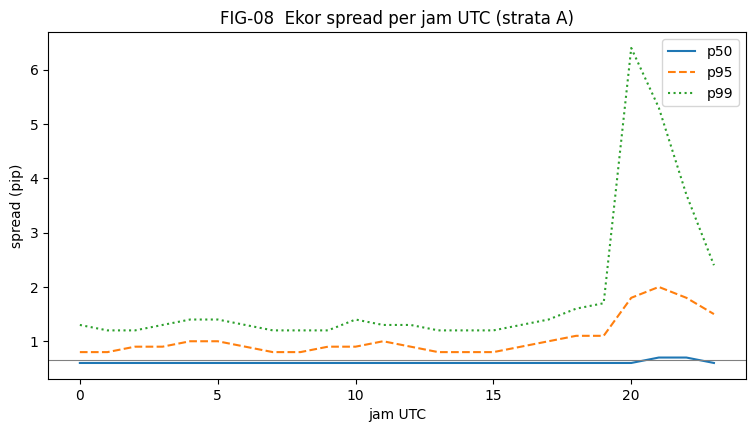

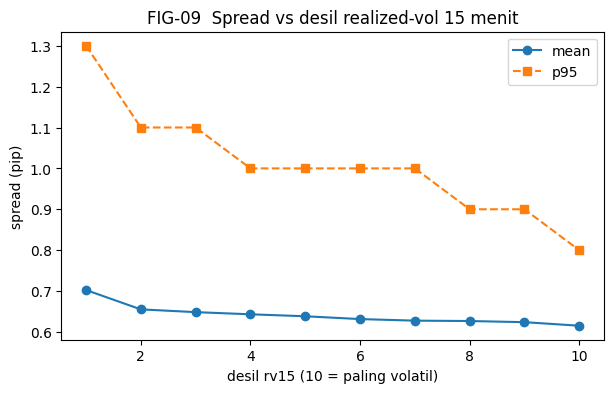

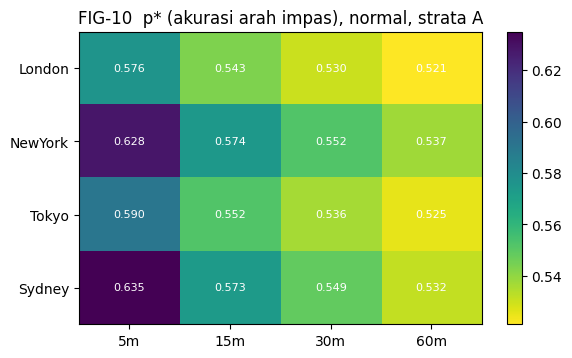

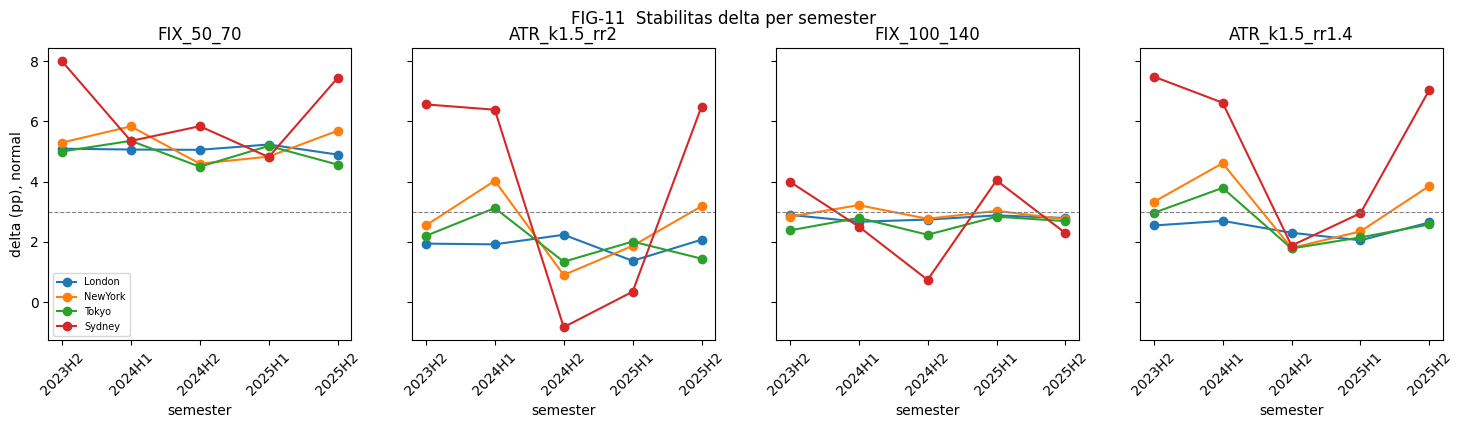

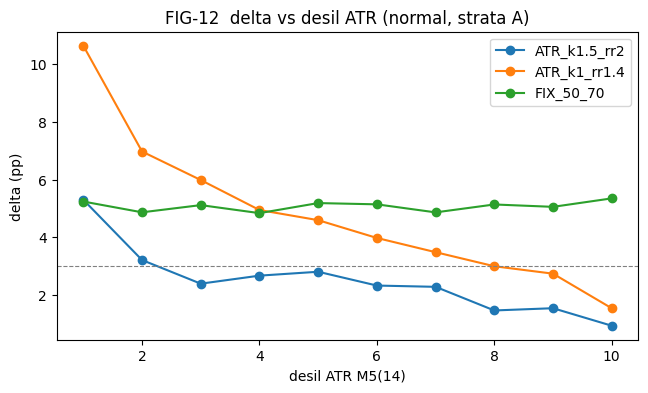

tersimpan 14 tabel CSV dan 5 gambar di reports\eda\2026-10-10

=== RINGKASAN ===
universe: strata A+B 2023-2025 (tanpa C), 2026 tidak dimuat | entri valid=184,731 (stride 5, horizon 120 mnt)
irisan diuji: 144 (tercile) + 48 (sesi) | VERDICT gerbang: LOLOS


In [16]:
"""FIG-08..12 dan penyimpanan tabel ke reports/eda/<tanggal>/."""
fig, ax = plt.subplots(figsize=(9, 4.5))
for col, style in (("p50", "-"), ("p95", "--"), ("p99", ":")):
    ax.plot(T_06_1B.index, T_06_1B[col], style, label=col)
ax.axhline(COST_DEFAULT, color="gray", lw=0.8)
ax.set(title="FIG-08  Ekor spread per jam UTC (strata A)", xlabel="jam UTC", ylabel="spread (pip)")
ax.legend()
fig.savefig(REPORT_DIR / "FIG-08_ekor_spread_per_jam.png", dpi=120, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(T_06_2A.index, T_06_2A["spread_mean"], "o-", label="mean")
ax.plot(T_06_2A.index, T_06_2A["spread_p95"], "s--", label="p95")
ax.set(
    title="FIG-09  Spread vs desil realized-vol 15 menit",
    xlabel="desil rv15 (10 = paling volatil)",
    ylabel="spread (pip)",
)
ax.legend()
fig.savefig(REPORT_DIR / "FIG-09_spread_vs_volatilitas.png", dpi=120, bbox_inches="tight")
plt.show()

heat = (
    T_06_4[T_06_4["strata"] == "A"]
    .pivot_table(index="sesi", columns="N_menit", values="p*_normal_s0", aggfunc="first")
    .reindex(SESSIONS)
)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
im = ax.imshow(heat.to_numpy(), cmap="viridis_r", aspect="auto")
ax.set_xticks(range(len(heat.columns)), [f"{c}m" for c in heat.columns])
ax.set_yticks(range(len(heat.index)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.iloc[i, j]:.3f}", ha="center", va="center", color="w", fontsize=8)
ax.set_title("FIG-10  p* (akurasi arah impas), normal, strata A")
fig.colorbar(im, ax=ax)
fig.savefig(REPORT_DIR / "FIG-10_heatmap_pstar.png", dpi=120, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, len(focus), figsize=(4.5 * len(focus), 3.8), sharey=True)
axes = np.atleast_1d(axes)
for ax, combo in zip(axes, focus, strict=False):
    for label in SESSIONS:
        ax.plot(T_06_6[combo].index, T_06_6[combo][label], "o-", label=label)
    ax.axhline(K1_NORMAL_PP, color="gray", lw=0.8, ls="--")
    ax.set(title=combo, xlabel="semester")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("delta (pp), normal")
axes[0].legend(fontsize=7)
fig.suptitle("FIG-11  Stabilitas delta per semester")
fig.savefig(REPORT_DIR / "FIG-11_stabilitas_semester.png", dpi=120, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4))
for combo in T_06_5E.columns:
    ax.plot(T_06_5E.index, T_06_5E[combo], "o-", label=combo)
ax.axhline(K1_NORMAL_PP, color="gray", lw=0.8, ls="--")
ax.set(
    title="FIG-12  delta vs desil ATR (normal, strata A)",
    xlabel="desil ATR M5(14)",
    ylabel="delta (pp)",
)
ax.legend()
fig.savefig(REPORT_DIR / "FIG-12_delta_vs_atr.png", dpi=120, bbox_inches="tight")
plt.show()

TABLES = {
    "T-06-1a_spread_sesi": T_06_1,
    "T-06-1b_spread_jam": T_06_1B,
    "T-06-1c_spread_semester_mean": T_06_1C,
    "T-06-1d_spread_semester_p95": T_06_1C_p95,
    "T-06-2a_spread_vs_rv": T_06_2A,
    "T-06-2b_spread_jam_tetap": T_06_2B,
    "T-06-3_biaya": T_06_3.set_index(["sesi", "skenario", "slip_pip"]),
    "T-06-4_grid_pstar": T_06_4.set_index(["strata", "N_menit", "sesi"]),
    "T-06-5_barrier_sesi": AGG["sess"].set_index(["scn", "combo", "session"]),
    "T-06-5_barrier_desil": AGG["dec"].set_index(["scn", "combo", "atr_dec"]),
    "T-06-5_barrier_B": AGG["B_sess"].set_index(["scn", "combo", "session"]),
    "T-06-6_barrier_semester": AGG["sess_sem"].set_index(["scn", "combo", "session", "sem"]),
    "T-06-7_gerbang_tercile": G_TER.set_index(["combo", "session", "atr_ter_s"]),
    "T-06-7_gerbang_sesi": G_SESS.set_index(["combo", "session"]),
}
for name, table in TABLES.items():
    table.to_csv(REPORT_DIR / f"{name}.csv", float_format="%.6g")
print(f"tersimpan {len(TABLES)} tabel CSV dan 5 gambar di {REPORT_DIR.relative_to(PROJECT_ROOT)}")
print()
print("=== RINGKASAN ===")
print(
    f"universe: strata A+B 2023-2025 (tanpa C), 2026 tidak dimuat | entri valid={N_ENT:,} (stride {STRIDE}, horizon {HORIZON} mnt)"
)
print(f"irisan diuji: {len(G_TER)} (tercile) + {len(G_SESS)} (sesi) | VERDICT gerbang: {VERDICT}")

## Kesimpulan (isi manual setelah membaca tabel)

- Spread: sesi/jam mana yang ekornya paling buruk, dan apakah pelebaran terkait volatilitas atau jam tetap?
- Arah N-menit: apakah ada sesi × N dengan p\* ≤ 0,53 (normal) dan ≤ 0,55 (stres)?
- Barrier: untuk 50/70 point, berapa delta per sesi, dan di desil ATR berapa delta turun di bawah 3 pp?
- Apakah barrier ATR lebih stabil/ramah biaya daripada 50/70 tetap?
- Keputusan gerbang (K1-K3): lanjut ke EDA-07 pada irisan mana, atau berhenti dan rumuskan ulang target?